# Assesstment Task 6: Natural Language Processing

In [ ]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

for pkg in ["stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
sns.set_style("whitegrid")
RANDOM_STATE = 42

Task 1 - Dataset Exploration and Analysis

In [ ]:
raw = pd.read_csv("spam.csv", encoding="latin-1")

print("Dataset dimensions (rows, columns):", raw.shape)
print("\nFirst 10 records:")
raw.head(10)

Dataset dimensions (rows, columns): (5572, 5)

First 10 records:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun y...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have been selected to receivea Ã¥Â£900 prize...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles...,NaN,NaN,NaN


In [ ]:
print("Missing values per column:")
print(raw.isnull().sum())

Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [ ]:
df = raw.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"])
df = df.rename(columns={"v1": "class", "v2": "message"})

print("Cleaned dataset dimensions:", df.shape)
print("Missing values after cleaning:\n", df.isnull().sum(), sep="")

n_dup_rows = df.duplicated().sum()
n_dup_msgs = df["message"].duplicated().sum()
print(f"\nDuplicate rows (class + message identical): {n_dup_rows}")
print(f"Duplicate messages (message text repeated):  {n_dup_msgs}")
print("\nExamples of the most repeated messages:")
df["message"].value_counts().head(5)

Cleaned dataset dimensions: (5572, 2)
Missing values after cleaning:
class      0
message    0
dtype: int64

Duplicate rows (class + message identical): 403
Duplicate messages (message text repeated):  403

Examples of the most repeated messages:


,count
message,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4
Okie,4


       count  percentage (%)
class                       
ham     4825           86.59
spam     747           13.41

Imbalance ratio (ham : spam) = 6.46 : 1


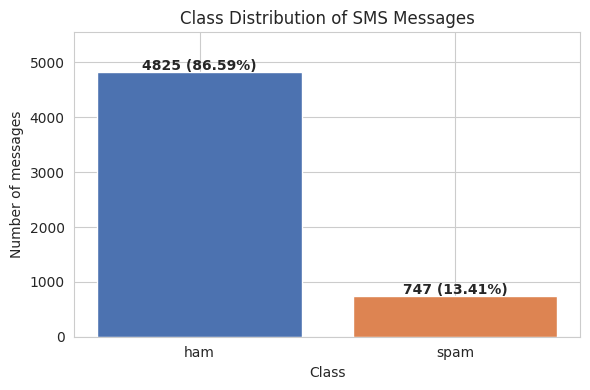

In [ ]:
# Spam and ham number and percentage
counts = df["class"].value_counts()
summary = pd.DataFrame({"count": counts, "percentage (%)": (counts / len(df) * 100).round(2)})
print(summary)
print(f"\nImbalance ratio (ham : spam) = {counts['ham'] / counts['spam']:.2f} : 1")

# Class distribution bar chart
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=["#4C72B0", "#DD8452"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 40, f"{v} ({v/len(df)*100:.2f}%)", ha="center", fontweight="bold")
ax.set_title("Class Distribution of SMS Messages")
ax.set_xlabel("Class"); ax.set_ylabel("Number of messages")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()

# Explanation about the dataset

The dataset consists of approximately 5,572 rows and 5 columns, containing messages classified as either ham or spam. During the initial examination of the dataset, 403 duplicate messages were identified, indicating that some messages appear more than once. These duplicates should be addressed during the data preprocessing stage to help prevent redundant information from affecting the training and evaluation of the classification model.

In terms of class distribution, ham messages account for 86.59% of the dataset, while spam messages represent only 13.41%. This distribution indicates that the dataset is imbalanced, as legitimate messages significantly outnumber spam messages. Such an imbalance may affect the performance of a machine learning model, as it may become more inclined to classify messages as ham due to the higher proportion of legitimate messages in the dataset.

Consequently, the model may achieve high overall accuracy while struggling to correctly identify spam messages. To address this issue, appropriate preprocessing techniques and evaluation metrics should be considered to ensure that the model can effectively distinguish between ham and spam messages. In particular, metrics such as precision, recall, F1-score, and the confusion matrix can provide a more comprehensive assessment of the model's performance than accuracy alone. These measures are important for evaluating the model's ability to identify spam messages while minimizing the incorrect classification of legitimate messages.

In [ ]:
#Task 2: NLP Text Preprocessing
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

df["clean_message"] = df["message"].apply(preprocess_text)

sample = df.sample(5, random_state=RANDOM_STATE)[["class", "message", "clean_message"]]
for i, (_, r) in enumerate(sample.iterrows(), 1):
    print(f"[{i}] ({r['class']})")
    print("   Original    :", r["message"])
    print("   Preprocessed:", r["clean_message"], "\n")

[1] (ham)
   Original    : Funny fact Nobody teaches volcanoes 2 erupt, tsunamis 2 arise, hurricanes 2 sway aroundn no 1 teaches hw 2 choose a wife Natural disasters just happens
   Preprocessed: funni fact nobodi teach volcano erupt tsunami aris hurrican sway aroundn teach hw choos wife natur disast happen 

[2] (ham)
   Original    : I sent my scores to sophas and i had to do secondary application for a few schools. I think if you are thinking of applying, do a research on cost also. Contact joke ogunrinde, her school is one me the less expensive ones
   Preprocessed: sent score sopha secondari applic school think think appli research cost also contact joke ogunrind school one less expens one 

[3] (spam)
   Original    : We know someone who you know that fancies you. Call 09058097218 to find out who. POBox 6, LS15HB 150p
   Preprocessed: know someon know fanci call find pobox ls hb p 

[4] (ham)
   Original    : Only if you promise your getting out as SOON as you can. And you'll tex

In [ ]:
#Prints messages that became empty after preprocessing.
print("Messages that are empty after preprocessing:", (df["clean_message"].str.strip() == "").sum())

Messages that are empty after preprocessing: 8


In [ ]:
raw_vocab = len(CountVectorizer().fit(df["message"]).vocabulary_)
clean_vocab = len(CountVectorizer().fit(df["clean_message"]).vocabulary_)
print(f"Vocabulary size - raw messages: {raw_vocab} | preprocessed messages: {clean_vocab} "
      f"({(1 - clean_vocab/raw_vocab)*100:.1f}% smaller)")

Vocabulary size - raw messages: 8679 | preprocessed messages: 6217 (28.4% smaller)


# Analysis question: Explain how text preprocessing can affect the classification performance of a Naive Bayes model.

Text preprocessing directly impacts a Naive Bayes classifier by cleaning the "noise" in our SMS data so the model can focus on the most important words. In this notebook, we simplified the text by converting everything to lowercase, removing punctuation, and stripping out common stopwords. This process reduced our vocabulary size by 28.4% (from 8,679 to 6,217 unique words). For a Naive Bayes model, which relies on calculating math probabilities for every single word, this reduction is incredibly beneficial. It prevents the model from getting confused by irrelevant words or duplicate variations, making the training process much faster and helping the model make more reliable predictions on new messages.

Specifically, the individual preprocessing steps we performed alter the classifier's performance in the following ways:

**>> Vocabulary Reduction**: Removing punctuation and
applying stemming (e.g., converting "Congratulations" to congratul) groups similar words together. This unifies different forms of a word into a single feature, giving Naive Bayes stronger, more reliable probability estimates.

**>> Eliminating Stopwords**: Removing highly frequent but uninformative words like "the", "to", or "and" prevents them from diluting the impact of highly predictive words like "win" or "free" during probability calculations.

**>> Information Loss Trade-off:** By removing all numbers and punctuation, some key spam markers (like currency symbols "£" or phone numbers) are lost. This extreme cleaning can occasionally make it harder for Naive Bayes to catch certain types of spam, meaning we must carefully balance cleaning noise with preserving important clues.

In [ ]:
#Task 3: Text Feature Correction
count_demo = CountVectorizer()
X_count_demo = count_demo.fit_transform(df["clean_message"])

tfidf_demo = TfidfVectorizer()
X_tfidf_demo = tfidf_demo.fit_transform(df["clean_message"])

for name, X, vec in [("CountVectorizer", X_count_demo, count_demo), ("TfidfVectorizer", X_tfidf_demo, tfidf_demo)]:
    feats = vec.get_feature_names_out()
    print(f"=== {name} ===")
    print("Feature matrix dimensions (documents x features):", X.shape)
    print("Vocabulary size:", len(vec.vocabulary_))
    print("10 example feature names:", list(feats[1000:1010]))
    print("Sparsity: {:.2f}% zeros\n".format(100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))))

=== CountVectorizer ===
Feature matrix dimensions (documents x features): (5572, 6217)
Vocabulary size: 6217
10 example feature names: ['cmon', 'cn', 'cncl', 'cnl', 'cnn', 'cnupdat', 'co', 'coach', 'coast', 'coat']
Sparsity: 99.87% zeros

=== TfidfVectorizer ===
Feature matrix dimensions (documents x features): (5572, 6217)
Vocabulary size: 6217
10 example feature names: ['cmon', 'cn', 'cncl', 'cnl', 'cnn', 'cnupdat', 'co', 'coach', 'coast', 'coat']
Sparsity: 99.87% zeros



In [ ]:
# Word frequency vs TF-IDF weight for the same message (illustration)
i = 2   # a spam message
tokens = df.loc[i, "clean_message"].split()
cnt_row  = X_count_demo[i].toarray().ravel()
tfidf_row = X_tfidf_demo[i].toarray().ravel()
idx = [count_demo.vocabulary_[t] for t in dict.fromkeys(tokens) if t in count_demo.vocabulary_]  # the default token pattern ignores 1-character tokens
print("Message:", df.loc[i, "message"][:120], "...")
pd.DataFrame({"term": [count_demo.get_feature_names_out()[j] for j in idx],
              "count": cnt_row[idx],
              "tf-idf weight": tfidf_row[idx].round(3)}).sort_values("tf-idf weight", ascending=False).head(10)

Message: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt r ...


,term,count,tf-idf weight
5,fa,2,0.526
1,entri,2,0.398
8,tkt,1,0.247
6,cup,1,0.226
14,std,1,0.220
3,comp,1,0.218
2,wkli,1,0.213
7,final,1,0.188
17,appli,1,0.187
13,question,1,0.185


# Analysis question: Explain the difference between word frequency and TF-IDF weighting. Which representation might be more suitable for spam classification, and why?

### The Difference Between CountVectorizer & TF-IDF

* **Word Frequency (CountVectorizer):** Simply counts how many times a word appears in a message. A word that appears 3 times gets a score of 3, regardless of how common or rare that word is across all other messages.
* **TF-IDF Weighting:** Scores a word based on two things: how often it appears in a single message (Term Frequency) balanced against how rare it is across the entire dataset (Inverse Document Frequency). Words that appear in almost every message get penalized with a very low score, while rare words get a much higher score.

### Which is Better for Spam Classification?

**TF-IDF** is generally more suitable for spam classification for several reasons:

* **Penalizes generic words:** Words like "morn", "call", or "get" are used frequently in both spam and normal messages (ham). TF-IDF lowers their score so they don't confuse the model.
* **Highlights unique spam triggers:** Spam messages often use specific words like "winner", "prize", or "txt". Since these words are rare in normal everyday texts, TF-IDF gives them a very high weight, making them stand out to the classifier.
* **Reduces message length bias:** Long messages naturally have higher raw word counts. TF-IDF normalizes these scores so a long, chatty message doesn't disproportionately skew the model's probability math.

In [ ]:
#Task 4: Naive Bayes Development Model
# Encode labels: ham = 0, spam = 1
y = (df["class"] == "spam").astype(int)
X = df["clean_message"]

# 70% train / 30% test, stratified, random_state = 42  (same split for both models)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Spam share  -> train: {:.2f}% | test: {:.2f}%".format(y_train.mean()*100, y_test.mean()*100))

Train size: 3900 | Test size: 1672
Spam share  -> train: 13.41% | test: 13.40%


In [ ]:
# Model A: CountVectorizer + Multinomial Naive Bayes
count_vec = CountVectorizer()
X_train_count = count_vec.fit_transform(X_train)
X_test_count  = count_vec.transform(X_test)

model_A = MultinomialNB()
model_A.fit(X_train_count, y_train)
pred_A = model_A.predict(X_test_count)

# Model B: TfidfVectorizer + Multinomial Naive Bayes
tfidf_vec = TfidfVectorizer()
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_test_tfidf  = tfidf_vec.transform(X_test)

model_B = MultinomialNB()
model_B.fit(X_train_tfidf, y_train)
pred_B = model_B.predict(X_test_tfidf)

print("Training feature matrix  - Model A (Count):", X_train_count.shape, "| Model B (TF-IDF):", X_train_tfidf.shape)
print("Vocabulary learned from training data only:", len(count_vec.vocabulary_), "terms")

# Predictions on the test dataset
preds = pd.DataFrame({
    "message": df.loc[X_test.index, "message"].values,
    "actual": y_test.map({0: "ham", 1: "spam"}).values,
    "Model A": pd.Series(pred_A).map({0: "ham", 1: "spam"}).values,
    "Model B": pd.Series(pred_B).map({0: "ham", 1: "spam"}).values,
})
print("\nFirst 10 test-set predictions:")
preds.head(10)

Training feature matrix  - Model A (Count): (3900, 5227) | Model B (TF-IDF): (3900, 5227)
Vocabulary learned from training data only: 5227 terms

First 10 test-set predictions:


,message,actual,Model A,Model B
0,You are a winner U have been specially selected 2 receive Ã¥Â£1000 cash or a 4* holida...,spam,spam,spam
1,I don't know but I'm raping dudes at poker,ham,ham,ham
2,We tried to contact you re your reply to our offer of a Video Phone 750 anytime any ne...,spam,spam,spam
3,"St andre, virgil's cream",ham,ham,ham
4,I have had two more letters from . I will copy them for you cos one has a message for ...,ham,ham,ham
5,Eh u remember how 2 spell his name... Yes i did. He v naughty make until i v wet.,ham,ham,ham
6,We know TAJ MAHAL as symbol of love. But the other lesser known facts 1. Mumtaz was Sh...,ham,ham,ham
7,The battery is for mr adewale my uncle. Aka Egbon,ham,ham,ham
8,I also thk too fast... Xy suggest one not me. U dun wan it's ok. Going 2 rain leh wher...,ham,ham,ham
9,"LOOK AT AMY URE A BEAUTIFUL, INTELLIGENT WOMAN AND I LIKE U A LOT. I KNOW U DONÃ¥ÃT L...",ham,ham,ham


In [ ]:
#Task 5: Model Evaluation and Comparison
def evaluate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, pos_label=1),
            "Recall": recall_score(y_true, y_pred, pos_label=1),
            "F1-score": f1_score(y_true, y_pred, pos_label=1),
            "False Positives": fp, "False Negatives": fn,
            "True Positives": tp, "True Negatives": tn}

res = pd.DataFrame({"Model A": evaluate(y_test, pred_A), "Model B": evaluate(y_test, pred_B)})
res.index.name = "Evaluation Metric"
rows = ["Accuracy", "Precision", "Recall", "F1-score", "False Positives", "False Negatives"]
display_tbl = pd.DataFrame({
    col: [f"{res.loc[r, col]:.4f}" if r in rows[:4] else str(int(res.loc[r, col])) for r in rows]
    for col in ["Model A", "Model B"]}, index=pd.Index(rows, name="Evaluation Metric"))
print("Comparison table (spam = positive class, test set n = %d)" % len(y_test))
display_tbl

Comparison table (spam = positive class, test set n = 1672)


,Model A,Model B
Evaluation Metric,,
Accuracy,0.9827,0.9665
Precision,0.9493,0.9941
Recall,0.9196,0.7545
F1-score,0.9342,0.8579
False Positives,11,1
False Negatives,18,55


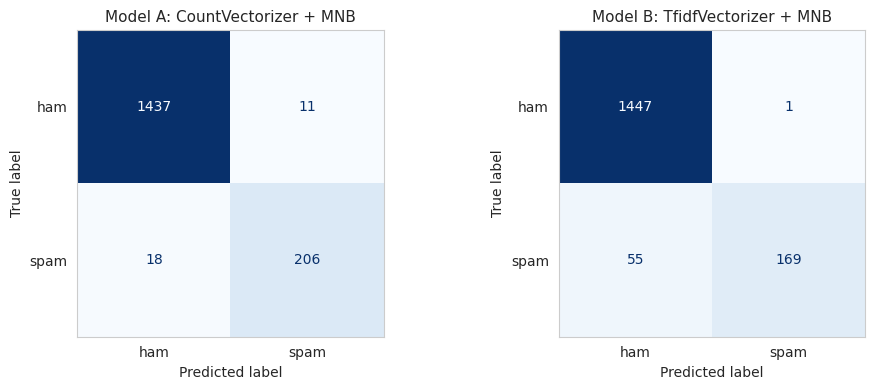

Model A classification report
              precision    recall  f1-score   support

         ham     0.9876    0.9924    0.9900      1448
        spam     0.9493    0.9196    0.9342       224

    accuracy                         0.9827      1672
   macro avg     0.9685    0.9560    0.9621      1672
weighted avg     0.9825    0.9827    0.9825      1672

Model B classification report
              precision    recall  f1-score   support

         ham     0.9634    0.9993    0.9810      1448
        spam     0.9941    0.7545    0.8579       224

    accuracy                         0.9665      1672
   macro avg     0.9787    0.8769    0.9194      1672
weighted avg     0.9675    0.9665    0.9645      1672



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, pred) in zip(axes, [("Model A: CountVectorizer + MNB", pred_A), ("Model B: TfidfVectorizer + MNB", pred_B)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title, fontsize=11); ax.grid(False)
plt.tight_layout(); plt.show()

print("Model A classification report"); print(classification_report(y_test, pred_A, target_names=["ham", "spam"], digits=4))
print("Model B classification report"); print(classification_report(y_test, pred_B, target_names=["ham", "spam"], digits=4))

# Analysis: Model Comparison and the Role of Precision & Recall in Spam Detection

### Which Model Performs Better?

* **Model A (CountVectorizer + Naive Bayes)** is overall the better and more balanced model for this task. It achieves an overall **Accuracy of 98.27%** and a strong **F1-score of 0.9342**.
* **Model B (TF-IDF + Naive Bayes)** struggles significantly with **Recall (75.45%)**, meaning it missed 55 spam messages (False Negatives) compared to Model A, which only missed 18.

---

### Why Precision and Recall are Crucial for Spam Detection

In spam filtering, we must look beyond basic accuracy because the dataset is highly imbalanced (mostly legitimate messages). Precision and recall represent two very different real-world consequences:

* **Precision (Focus on avoiding False Positives):**
  * *What it means:* Out of all messages the model flagged as spam, how many actually were spam?
  * *Why it matters:* This is the most critical metric for user trust. A false positive means a **legitimate message (like an urgent email from a boss or bank) is sent to the spam folder**. Model B has near-perfect Precision (99.41%, only 1 false positive), whereas Model A had 11 false positives.

* **Recall (Focus on avoiding False Negatives):**
  * *What it means:* Out of all the actual spam messages in the dataset, how many did the model successfully catch?
  * *Why it matters:* A false negative means a **spam message successfully slips into the user's inbox**. While less damaging than losing an important email, too many false negatives make the spam filter useless. Model A caught 91.96% of spam, while Model B only caught 75.45%.

In [ ]:
# Task 6: Testing with Unseen Message
# Select the better model automatically using the spam-class F1-score
best_name = "Model A" if res.loc["F1-score", "Model A"] >= res.loc["F1-score", "Model B"] else "Model B"
best_model, best_vec = (model_A, count_vec) if best_name == "Model A" else (model_B, tfidf_vec)
print("Better-performing model (highest spam F1-score):", best_name)

new_messages = [
    "Congratulations! You have won a free cash prize.",
    "Good morning, our class starts at 8 AM tomorrow.",
    "Claim your reward now by clicking this link.",
    "Please submit your assignment before Friday.",
    "URGENT! You have been selected to receive a cash bonus.",
]
# Apply the SAME preprocessing and the vectorizer fitted on the training data
new_clean = [preprocess_text(m) for m in new_messages]
X_new = best_vec.transform(new_clean)
proba = best_model.predict_proba(X_new)          # columns: [P(ham), P(spam)]
labels = np.where(proba[:, 1] >= 0.5, "spam", "ham")

result = pd.DataFrame({
    "No.": range(1, 6),
    "SMS Message": new_messages,
    "Preprocessed": new_clean,
    "Prediction": labels,
    "P(ham)": proba[:, 0].round(4),
    "P(spam)": proba[:, 1].round(4),
    "Probability of predicted class": np.maximum(proba[:, 0], proba[:, 1]).round(4),
})
result

Better-performing model (highest spam F1-score): Model A


,No.,SMS Message,Preprocessed,Prediction,P(ham),P(spam),Probability of predicted class
0,1,Congratulations! You have won a free cash prize.,congratul free cash prize,spam,0.0001,0.9999,0.9999
1,2,"Good morning, our class starts at 8 AM tomorrow.",good morn class start tomorrow,ham,1.0000,0.0000,1.0000
2,3,Claim your reward now by clicking this link.,claim reward click link,spam,0.0002,0.9998,0.9998
3,4,Please submit your assignment before Friday.,pleas submit assign friday,ham,0.9364,0.0636,0.9364
4,5,URGENT! You have been selected to receive a cash bonus.,urgent select receiv cash bonu,spam,0.0000,1.0000,1.0000


In [ ]:
# Supporting evidence for the analysis: which words push each message toward spam or ham?
# log P(word|spam) - log P(word|ham) from the trained model (positive = spam indicator)
vocab = best_vec.vocabulary_
log_ratio = best_model.feature_log_prob_[1] - best_model.feature_log_prob_[0]
for i, c in enumerate(new_clean, 1):
    rows = [(w, round(log_ratio[vocab[w]], 2)) for w in dict.fromkeys(c.split()) if w in vocab]
    unseen = [w for w in dict.fromkeys(c.split()) if w not in vocab]
    print(f"[{i}] spam-evidence per stemmed word:", sorted(rows, key=lambda x: -x[1]), "| not in vocabulary:", unseen)
print("\nPrior P(spam) learned from training data: {:.4f}".format(np.exp(best_model.class_log_prior_[1])))

[1] spam-evidence per stemmed word: [('prize', np.float64(4.94)), ('free', np.float64(2.24)), ('cash', np.float64(2.19)), ('congratul', np.float64(2.16))] | not in vocabulary: []
[2] spam-evidence per stemmed word: [('start', np.float64(-0.38)), ('tomorrow', np.float64(-1.51)), ('good', np.float64(-1.91)), ('class', np.float64(-2.75)), ('morn', np.float64(-3.18))] | not in vocabulary: []
[3] spam-evidence per stemmed word: [('claim', np.float64(5.24)), ('reward', np.float64(2.47)), ('click', np.float64(1.37)), ('link', np.float64(1.08))] | not in vocabulary: []
[4] spam-evidence per stemmed word: [('pleas', np.float64(0.45)), ('submit', np.float64(0.17)), ('friday', np.float64(-1.44))] | not in vocabulary: ['assign']
[5] spam-evidence per stemmed word: [('bonu', np.float64(3.57)), ('select', np.float64(2.94)), ('urgent', np.float64(2.7)), ('receiv', np.float64(2.47)), ('cash', np.float64(2.19))] | not in vocabulary: []

Prior P(spam) learned from training data: 0.1341


In [ ]:
both = pd.DataFrame({
    "No.": range(1, 6),
    "Model A P(spam)": model_A.predict_proba(count_vec.transform(new_clean))[:, 1].round(4),
    "Model B P(spam)": model_B.predict_proba(tfidf_vec.transform(new_clean))[:, 1].round(4),
})
both

,No.,Model A P(spam),Model B P(spam)
0,1,0.9999,0.8583
1,2,0.0000,0.0031
2,3,0.9998,0.7450
3,4,0.0636,0.1162
4,5,1.0000,0.9229


# Analysis: Explaining Unexpected Predictions on Unseen Messages

### 1. Identify the Unexpected Prediction: Message [4]
* **The Message:** *"Please submit your assignment before Friday."*
* **The Issue:** While both models correctly classified it as **ham** (legitimate), Model A assigned it a surprisingly high **6.36% probability of being spam**, and Model B assigned it an even higher **11.62% probability of being spam**.
* **Why this is unexpected:** This is a routine, non-commercial academic message that contains zero typical spam characteristics (no cash offers, links, or urgency).

### 2. Reasons for this Behavior

* **The Out-of-Vocabulary Term (`assign`):** The word *"assignment"* (stemmed to `assign`) was completely **absent from the training dataset** vocabulary. When Naive Bayes encounters a word it has never seen, it cannot use it to establish a strong connection to normal messages (ham).
* **The Presence of `pleas` and `submit`:** Since `assign` was ignored, the classification relied heavily on the remaining words.
  * In the training data, the word **`pleas`** (stemmed from "please") actually has a slightly positive log-probability ratio of **0.45**, meaning it appears moderately often in spam requests (e.g., "Please call...", "Please claim...").
  * The word **`submit`** also carried a weak positive spam signal of **0.17**.
* **Resulting Bias:** Because the dominant safe word (`assign`) was invisible, and the remaining words (`pleas` and `submit`) are frequently associated with spam calls-to-action, the probability of spam was falsely inflated.